## Introduction

Welcome to my notebook on **Exploratory Data Analysis for Telecom Customer Churn**. Here, we dive into a telecom customers dataset, using data analysis to uncover patterns that explains the reasons behind customer churn. This exploration will help us make informed decisions to enhance customer retention strategies.

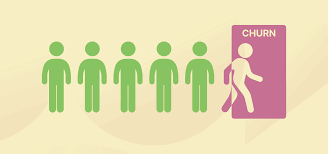

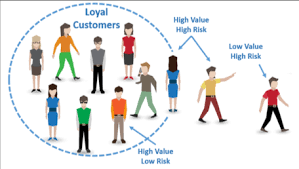

## Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Getting Our Data

we will start by reading our data from a csv file using read_csv method in pandas

In [2]:
data_customer=pd.read_csv("/kaggle/input/telecom-customer-churn-by-maven-analytics/telecom_customer_churn.csv")

In [3]:
data_customer.head()

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [4]:
data_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   object 
 1   Gender                             7043 non-null   object 
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   object 
 4   Number of Dependents               7043 non-null   int64  
 5   City                               7043 non-null   object 
 6   Zip Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number of Referrals                7043 non-null   int64  
 10  Tenure in Months                   7043 non-null   int64  
 11  Offer                              7043 non-null   objec

## Data Analysis

First we are going to remove the irrelevant features

In [5]:
data_customer.drop(columns = ['Customer ID', 'Zip Code', 'Latitude', 'Longitude'],axis=1 ,inplace = True)

(array([0, 1, 2]),
 [Text(0, 0, 'Stayed'), Text(1, 0, 'Churned'), Text(2, 0, 'Joined')])

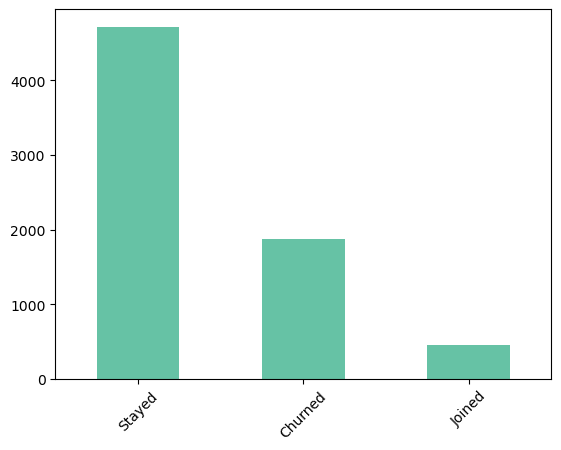

In [6]:
data_customer["Customer Status"].value_counts().plot(kind='bar',stacked=True, colormap = 'Set2')
plt.xticks(rotation=45)

We are going to remove the Joined Catagories because it doen't provide us any information about the churn rate

In [7]:
data_customer = data_customer[data_customer["Customer Status"]!= "Joined"]
len(data_customer)

6589

### Exploring Chrun Reasons

Let's Start by exploring the reasons of the churn rate

<Axes: xlabel='count', ylabel='Churn Category'>

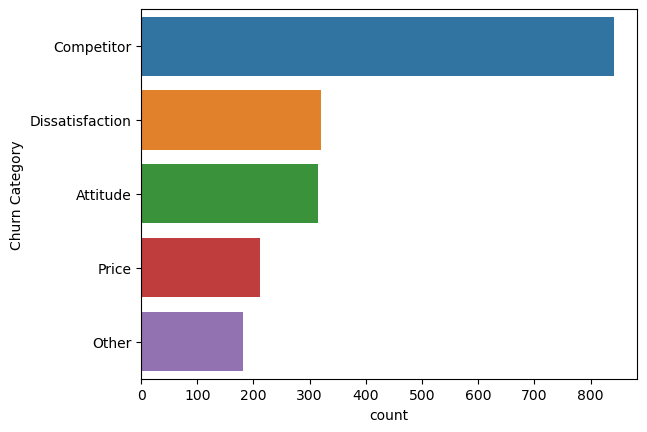

In [8]:
sns.countplot(data=data_customer,y="Churn Category",order = data_customer["Churn Category"].value_counts().index)

<Axes: xlabel='count', ylabel='Churn Reason'>

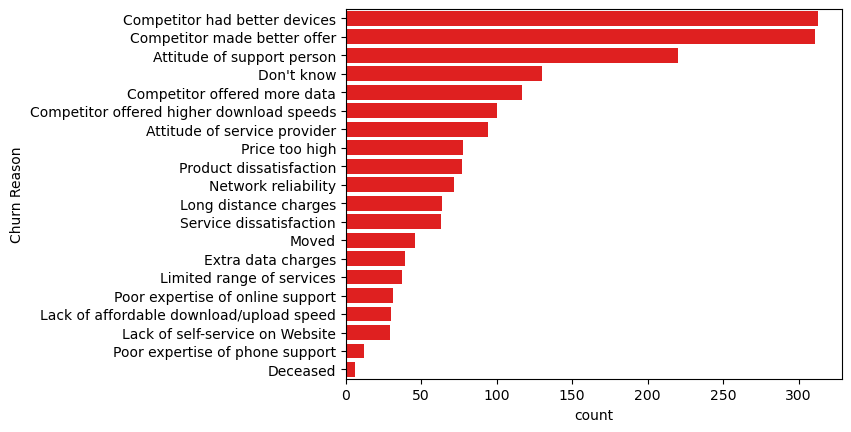

In [9]:
sns.countplot(data=data_customer,y="Churn Reason",order = data_customer["Churn Reason"].value_counts().index,color = 'red')

From these 2 plots we can start to have an idea about the Customer Churn Reasons so Most of the churn was because that :
* The competitor had better offers and technologie in general
* This company had a bad Attitude and Service
* This company charged a lot 

Now Let's Try and have an understanding of our features

## Data Exploring : Numerical / Catagorical features

First of all we are going to group the catagorical and numerical features

In [10]:
cat  = list(data_customer.select_dtypes(include='object').columns)
num = list(data_customer.select_dtypes(exclude='object').columns)

### Numerical

#### Histogram plot

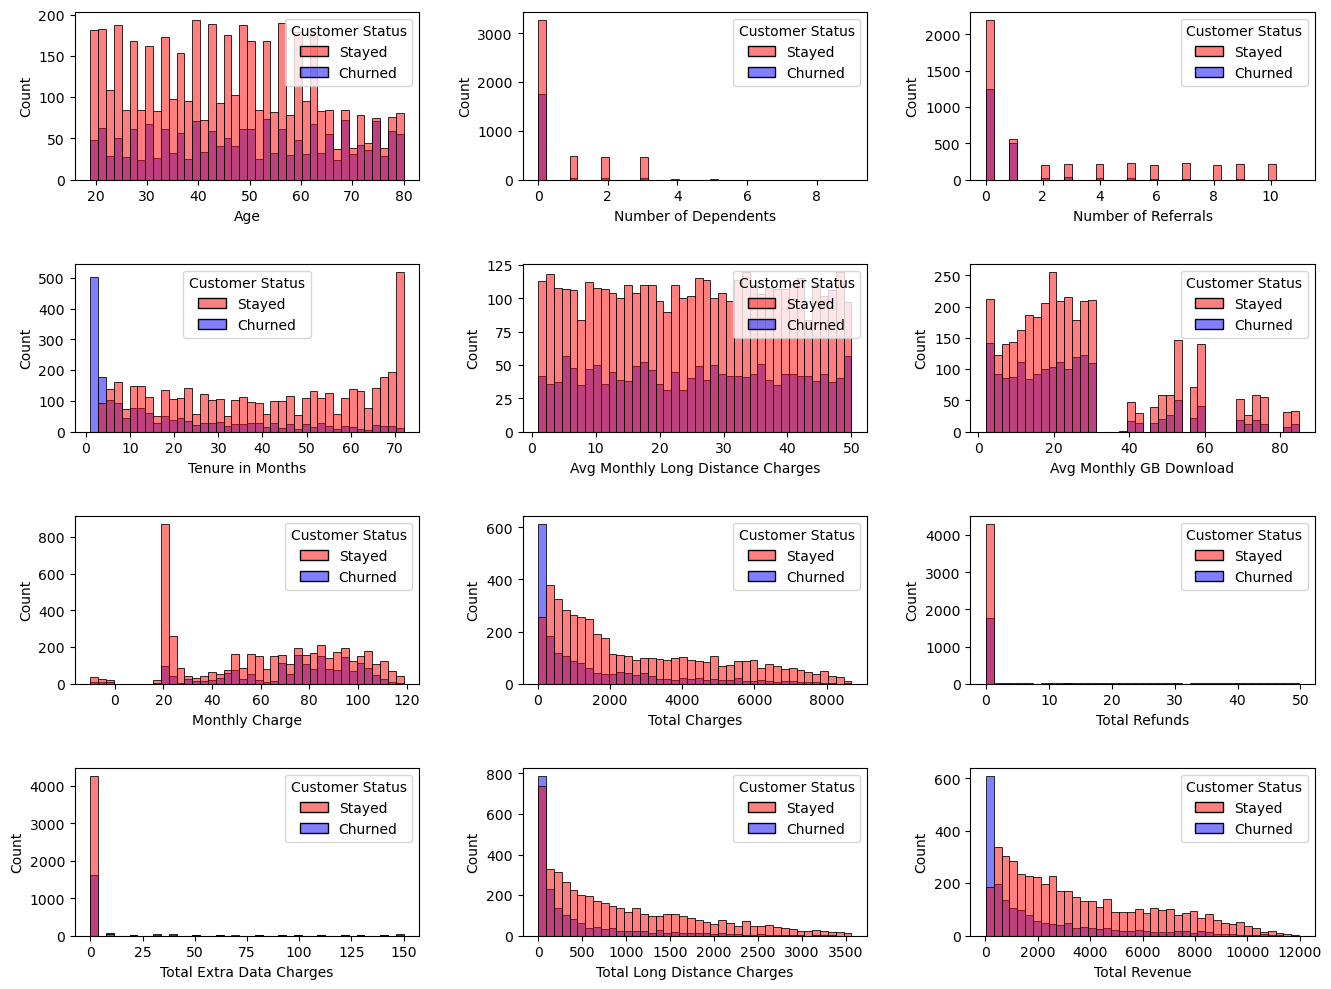

In [11]:
fig, axes = plt.subplots(4,3 , figsize=(16,12))
plt.subplots_adjust(wspace=0.3, hspace=0.5)
axes = axes.flatten()
for i in range(len(num)):
    sns.histplot(x = data_customer[num[i]], hue = data_customer['Customer Status'], palette = ["red","blue"], bins = 40,ax=axes[i])

### Summary for Numerical Features

We can notice that 3 features here strongly influence the churn rate 
* **Tensure in Months** : A customer is more likely to churn in the first 4 months since he joined
* **Total Charges** We can notice that the amount of Total charge for churn customers is significantly lower than the Stayed in customers
* **Total Revenue**

#### Heat map

<Axes: >

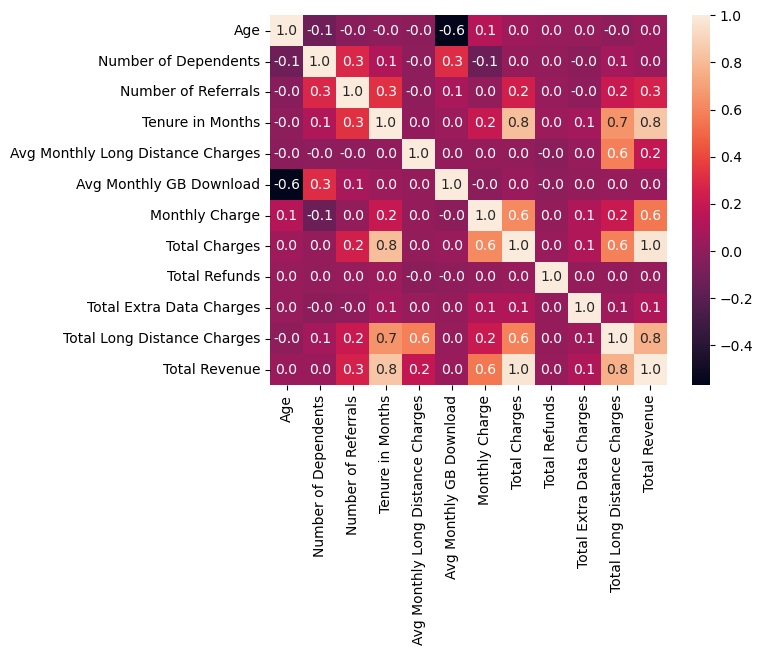

In [12]:
sns.heatmap(data_customer[num].corr(), annot = True,fmt='.1f') 

This heatmap shows us that there is no big corrolation between our varaibles apart from the ones that are pretty clear so this means that our variables in general are not in a linear relation

### Catagorical

In [13]:
cat.remove("City")
cat.remove("Churn Category")
cat.remove("Churn Reason")

We are going to use these plots below to have an understanding how does how catagorical features influence the Churn rate

#### Countplot

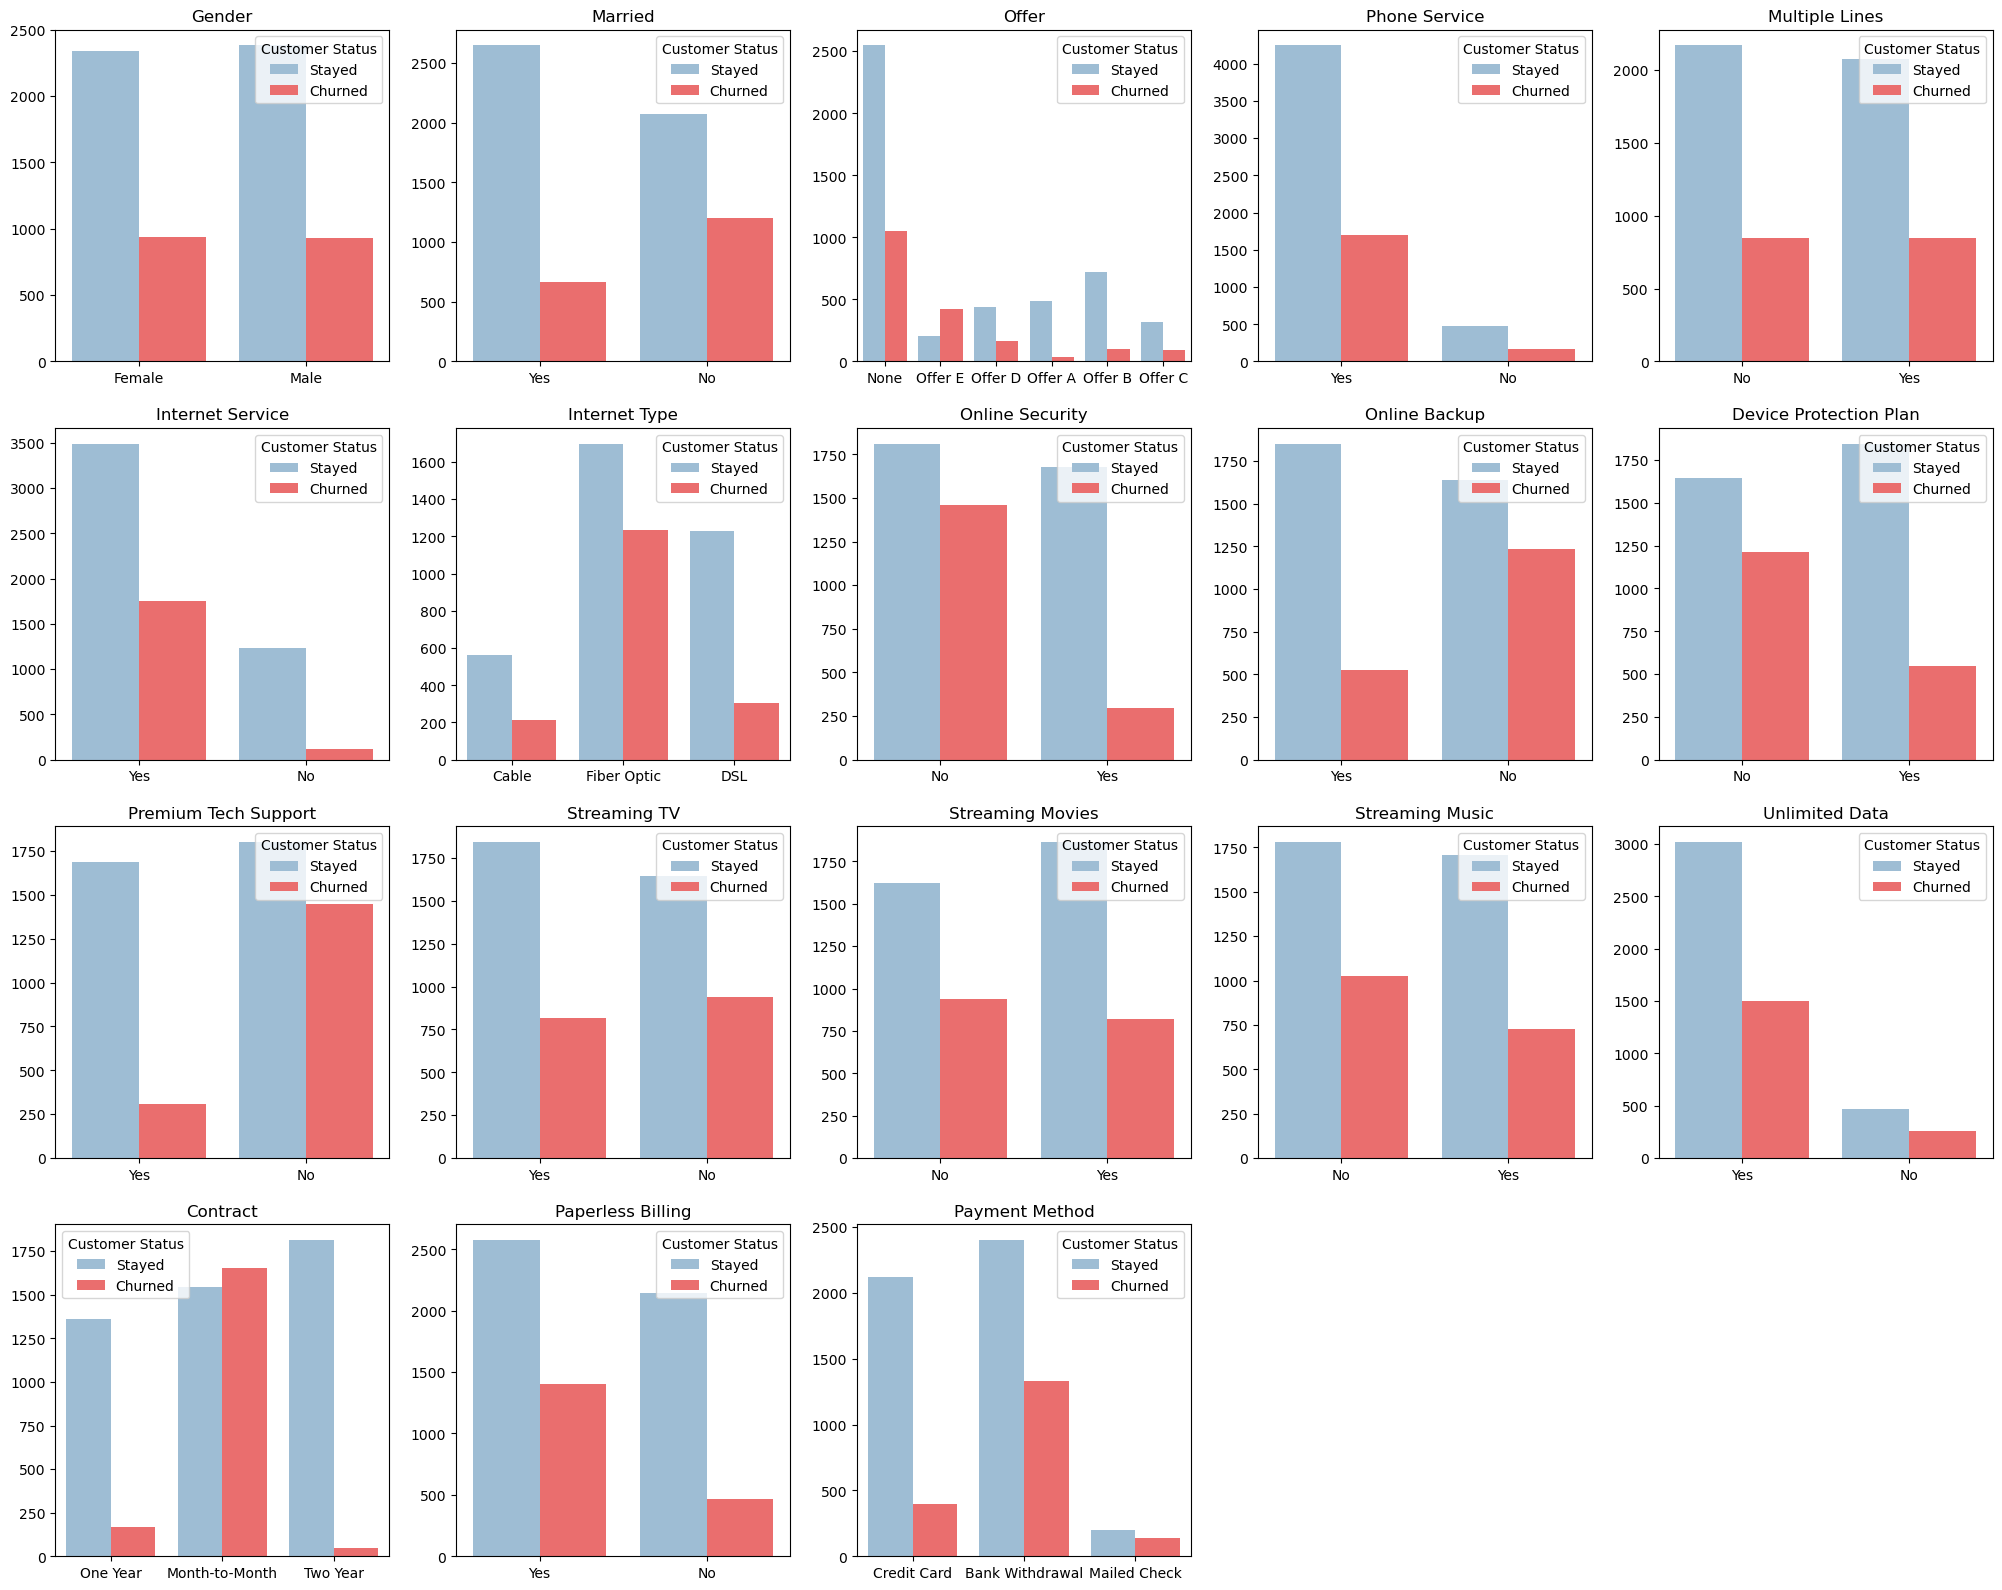

In [14]:
fig = plt.figure(figsize = (25, 25))
data_cat=data_customer[cat]
i=1
for x in cat[:-1]:
    plt.subplot(5, 5, i)
    ax=sns.countplot(data =data_cat , x = data_cat[x], hue ='Customer Status', palette = ["#95BEDD", '#FF5959'])
    ax.set(xlabel = None, ylabel = None)
    plt.title(str(x), loc='center')
    i+=1
plt.show()

#### Line plot

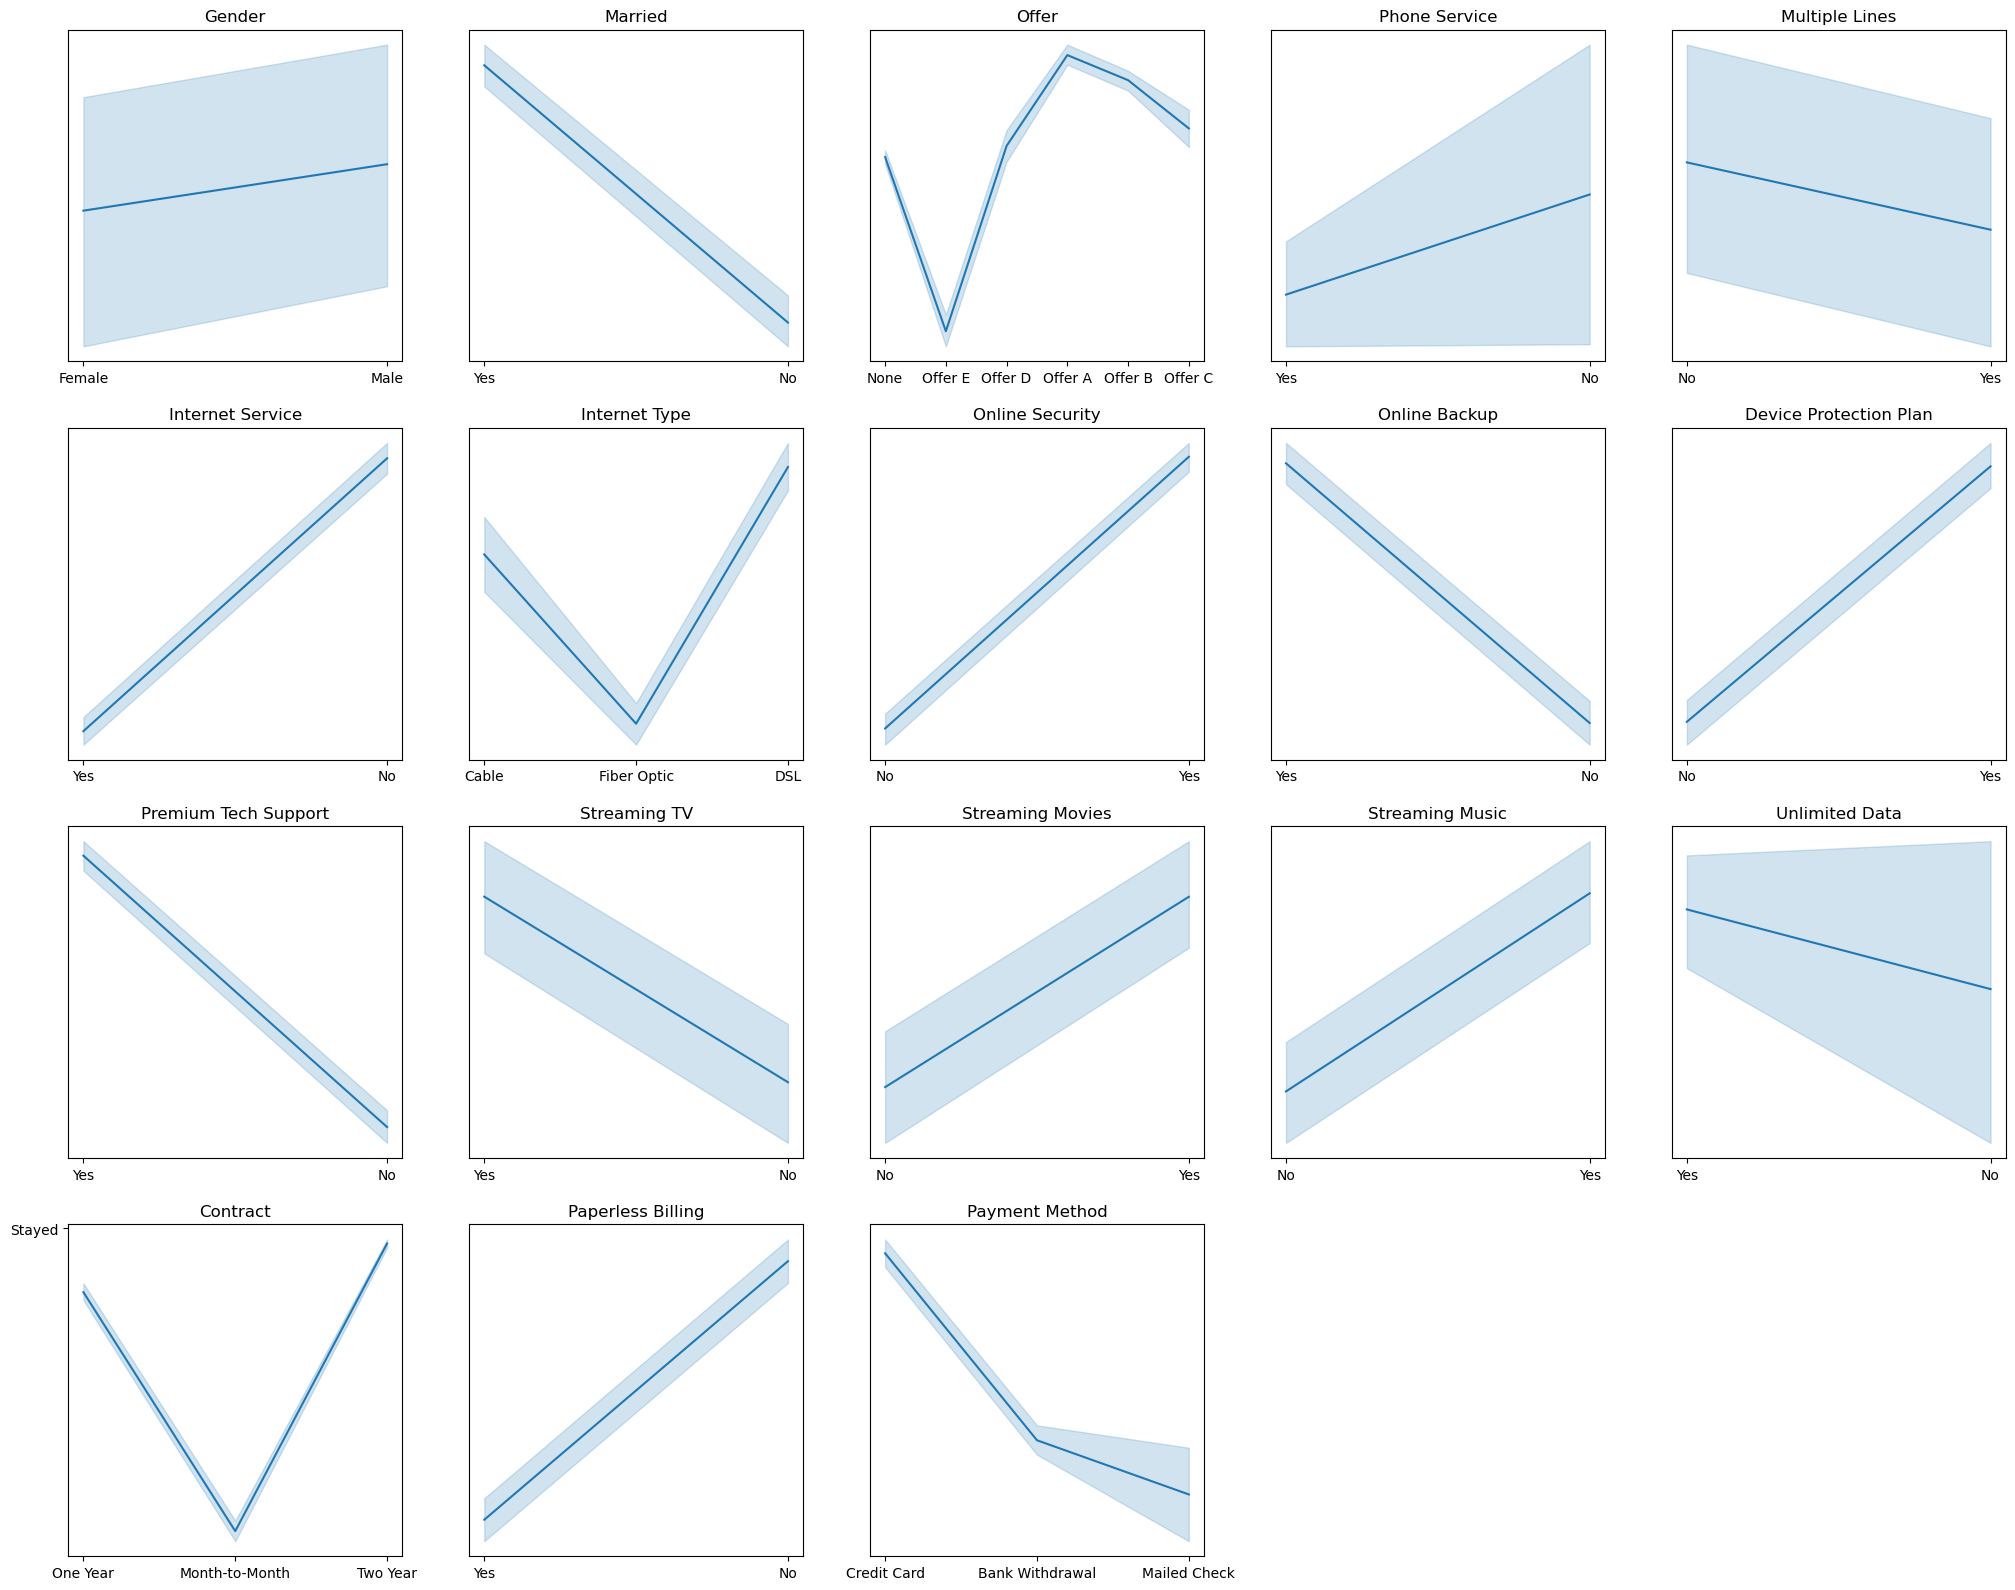

In [15]:
fig = plt.figure(figsize = (25, 25))
data_cat=data_customer[cat]
i=1
for x in cat[:-1]:
    plt.subplot(5, 5, i)
    ax=sns.lineplot(data =data_cat , x = data_cat[x],y ='Customer Status')
    ax.set(xlabel = None, ylabel = None)
    plt.title(str(x), loc='center')
    i+=1
plt.show()

#### PieChart

We are going to use the pie chart to distinguish the composition of each catagory 

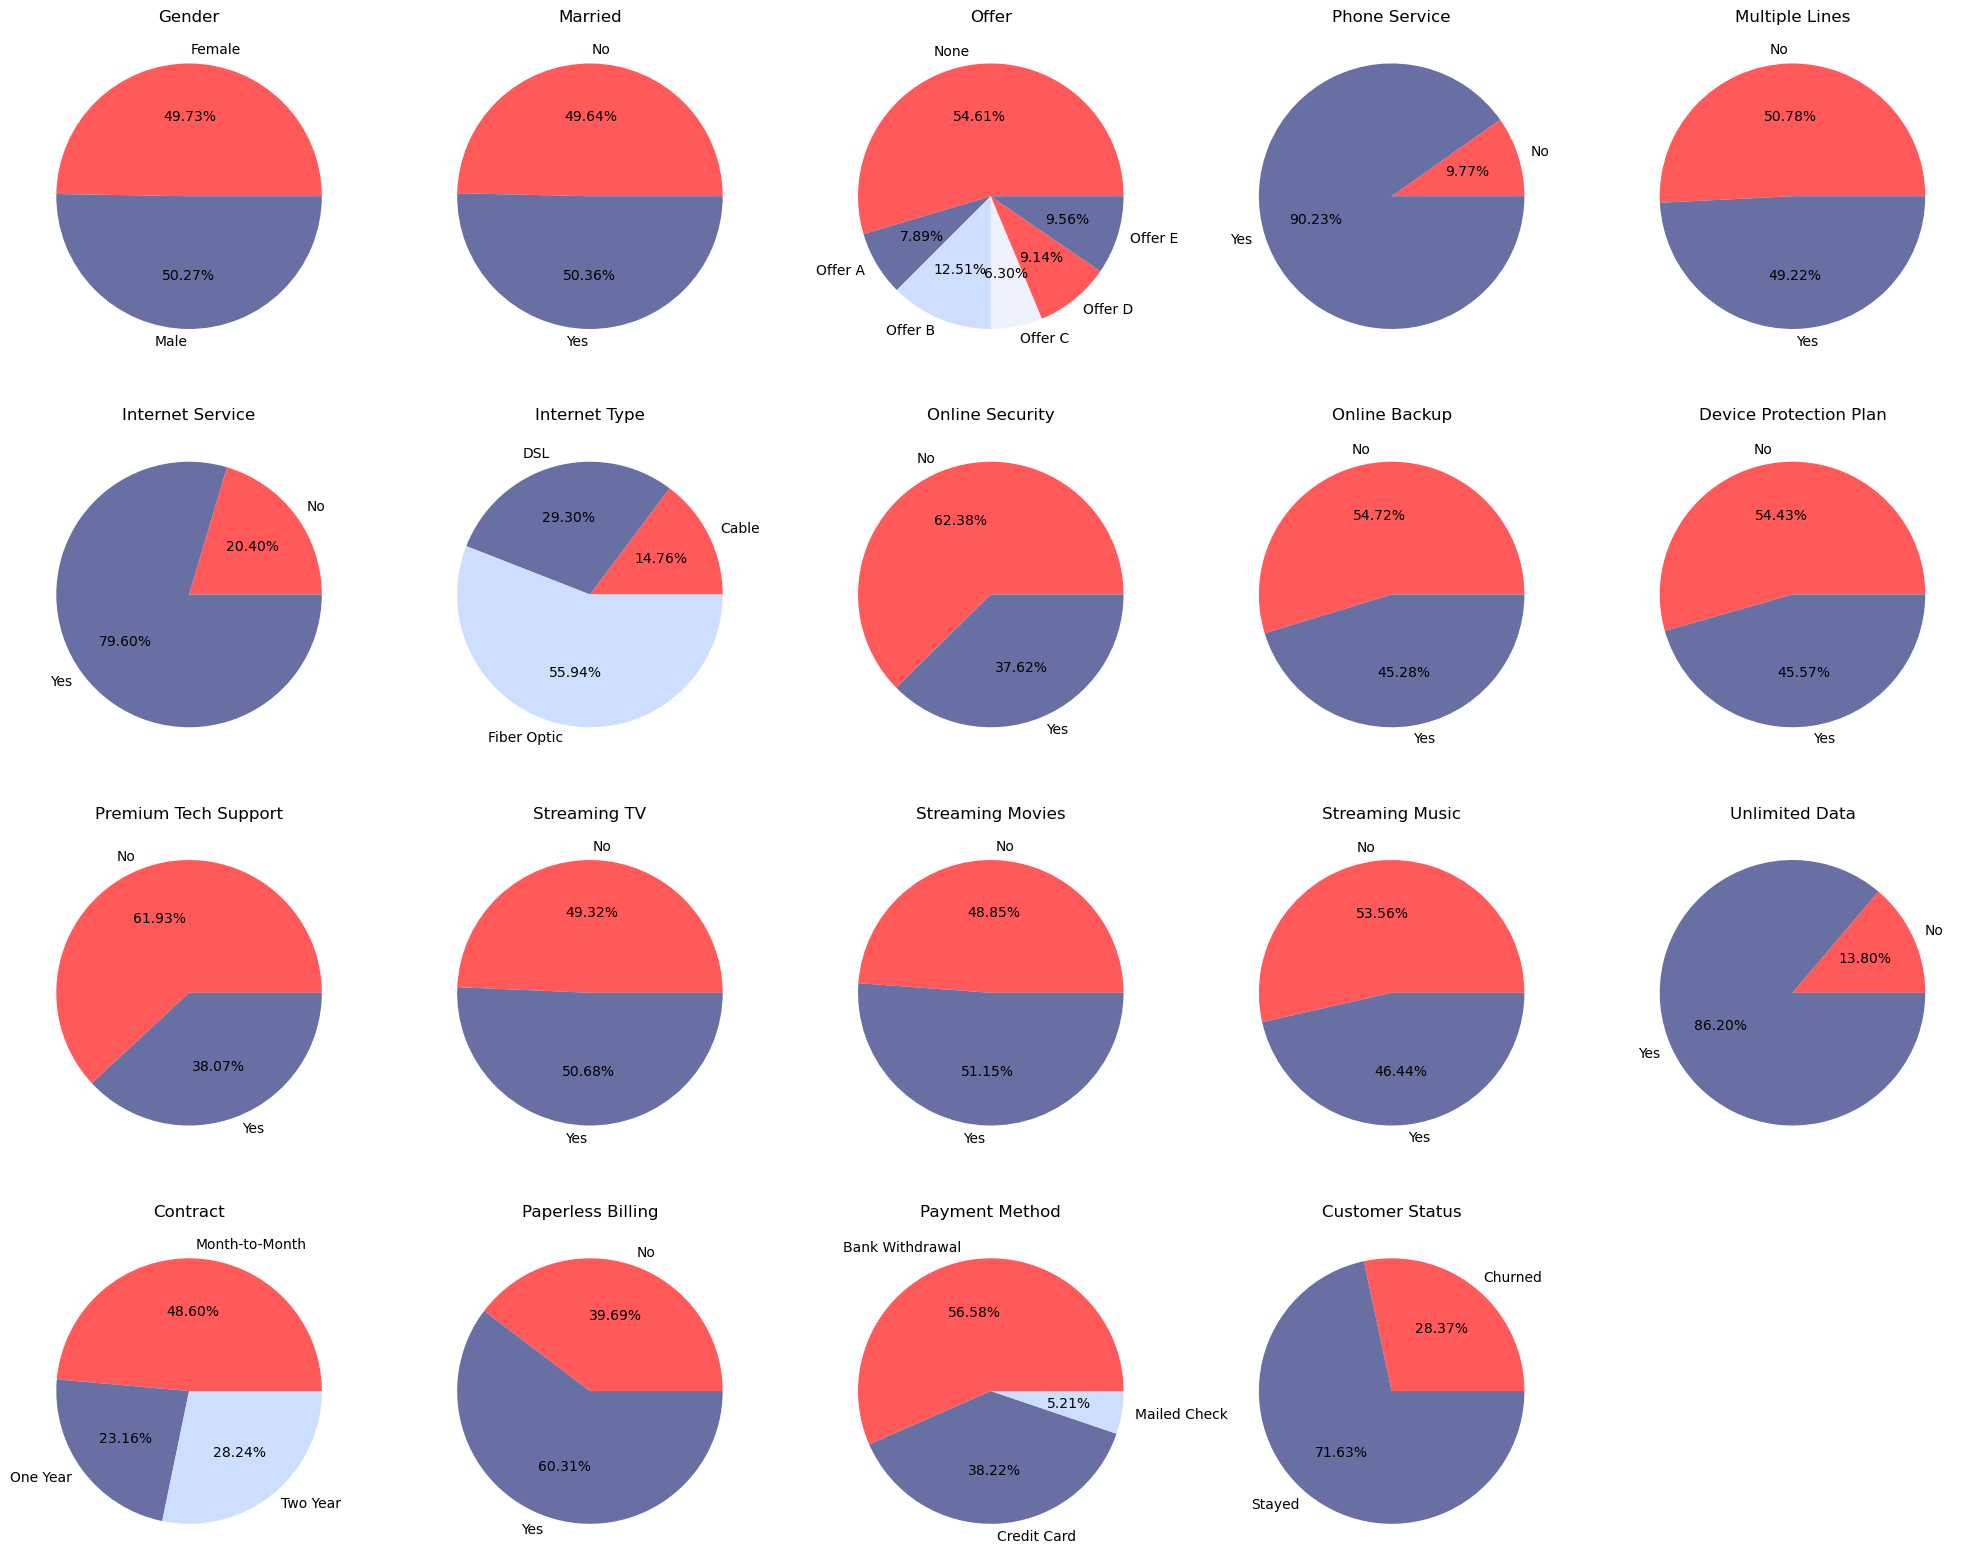

In [16]:
fig = plt.figure(figsize = (25, 25))
data_cat=data_customer[cat]
i=1
for x in cat:
    plt.subplot(5, 5, i)
    ax = data_customer.groupby([x]).size().plot(kind = 'pie', autopct = '%.2f%%', colors = ['#FF5959', '#676FA3','#CDDEFF', '#EEF2FF'])
    ax.set(xlabel = None, ylabel = None)
    plt.title(str(x), loc='center')
    i+=1
plt.show()

### Summary For Catagorical Features

We can notice that some feature are strongly responsible for this churn rate :
* **Offer** : Most clients didn't get any offer types which can be caused by the bad communication and service of the industry .Also we should have a look at the offer type E because it still has a bad churn rate
* **Service** : It looks like client who have either a phone service or an internet service are more likely to churn which reflectes the poor service
* **Internet Type** : The majorety of churn customers are FiberOptic clients
* **Features** : the customers who are enrolled in Online security, Online Backup,Device Protection Plan,Premium Tech Support, Unlimited Data are less likely to churn
* **Contract** : Clients with Monthly subscriptions and Bank Withdrawal are the most Churn of all others

## Analysis Between High Value Customers and Churn Customers

### High Value Clients Analysis

Customers who have provided revenue higher than the company's average and have maintained their engagement are regarded as valuable and loyal clients.

In [17]:
data_customer['Total Revenue'].mean()

3235.2180816512373

In [18]:
data_customer['High Value'] = 0
data_customer.loc[data_customer['Total Revenue'] > 3235.2180816512373, 'High Value'] = 'High Value'

In [19]:
df_high_value = data_customer[data_customer['High Value'] == 'High Value']
df_high_value.head()

,Gender,Age,Married,Number of Dependents,City,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,...,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason,High Value
6,Female,67,Yes,0,Lompoc,1,71,Offer A,Yes,9.96,...,109.70,7904.25,0.0,0,707.16,8611.41,Stayed,NaN,NaN,High Value
7,Male,52,Yes,0,Napa,8,63,Offer B,Yes,12.96,...,84.65,5377.80,0.0,20,816.48,6214.28,Stayed,NaN,NaN,High Value
9,Female,43,Yes,1,Sheridan,3,65,None,Yes,28.46,...,90.45,5957.90,0.0,0,1849.90,7807.80,Stayed,NaN,NaN,High Value
11,Female,25,Yes,2,Sunnyvale,2,72,None,Yes,16.01,...,116.80,8456.75,0.0,0,1152.72,9609.47,Stayed,NaN,NaN,High Value
13,Female,32,No,0,La Mesa,0,72,Offer A,Yes,2.25,...,101.30,7261.25,0.0,0,162.00,7423.25,Stayed,NaN,NaN,High Value


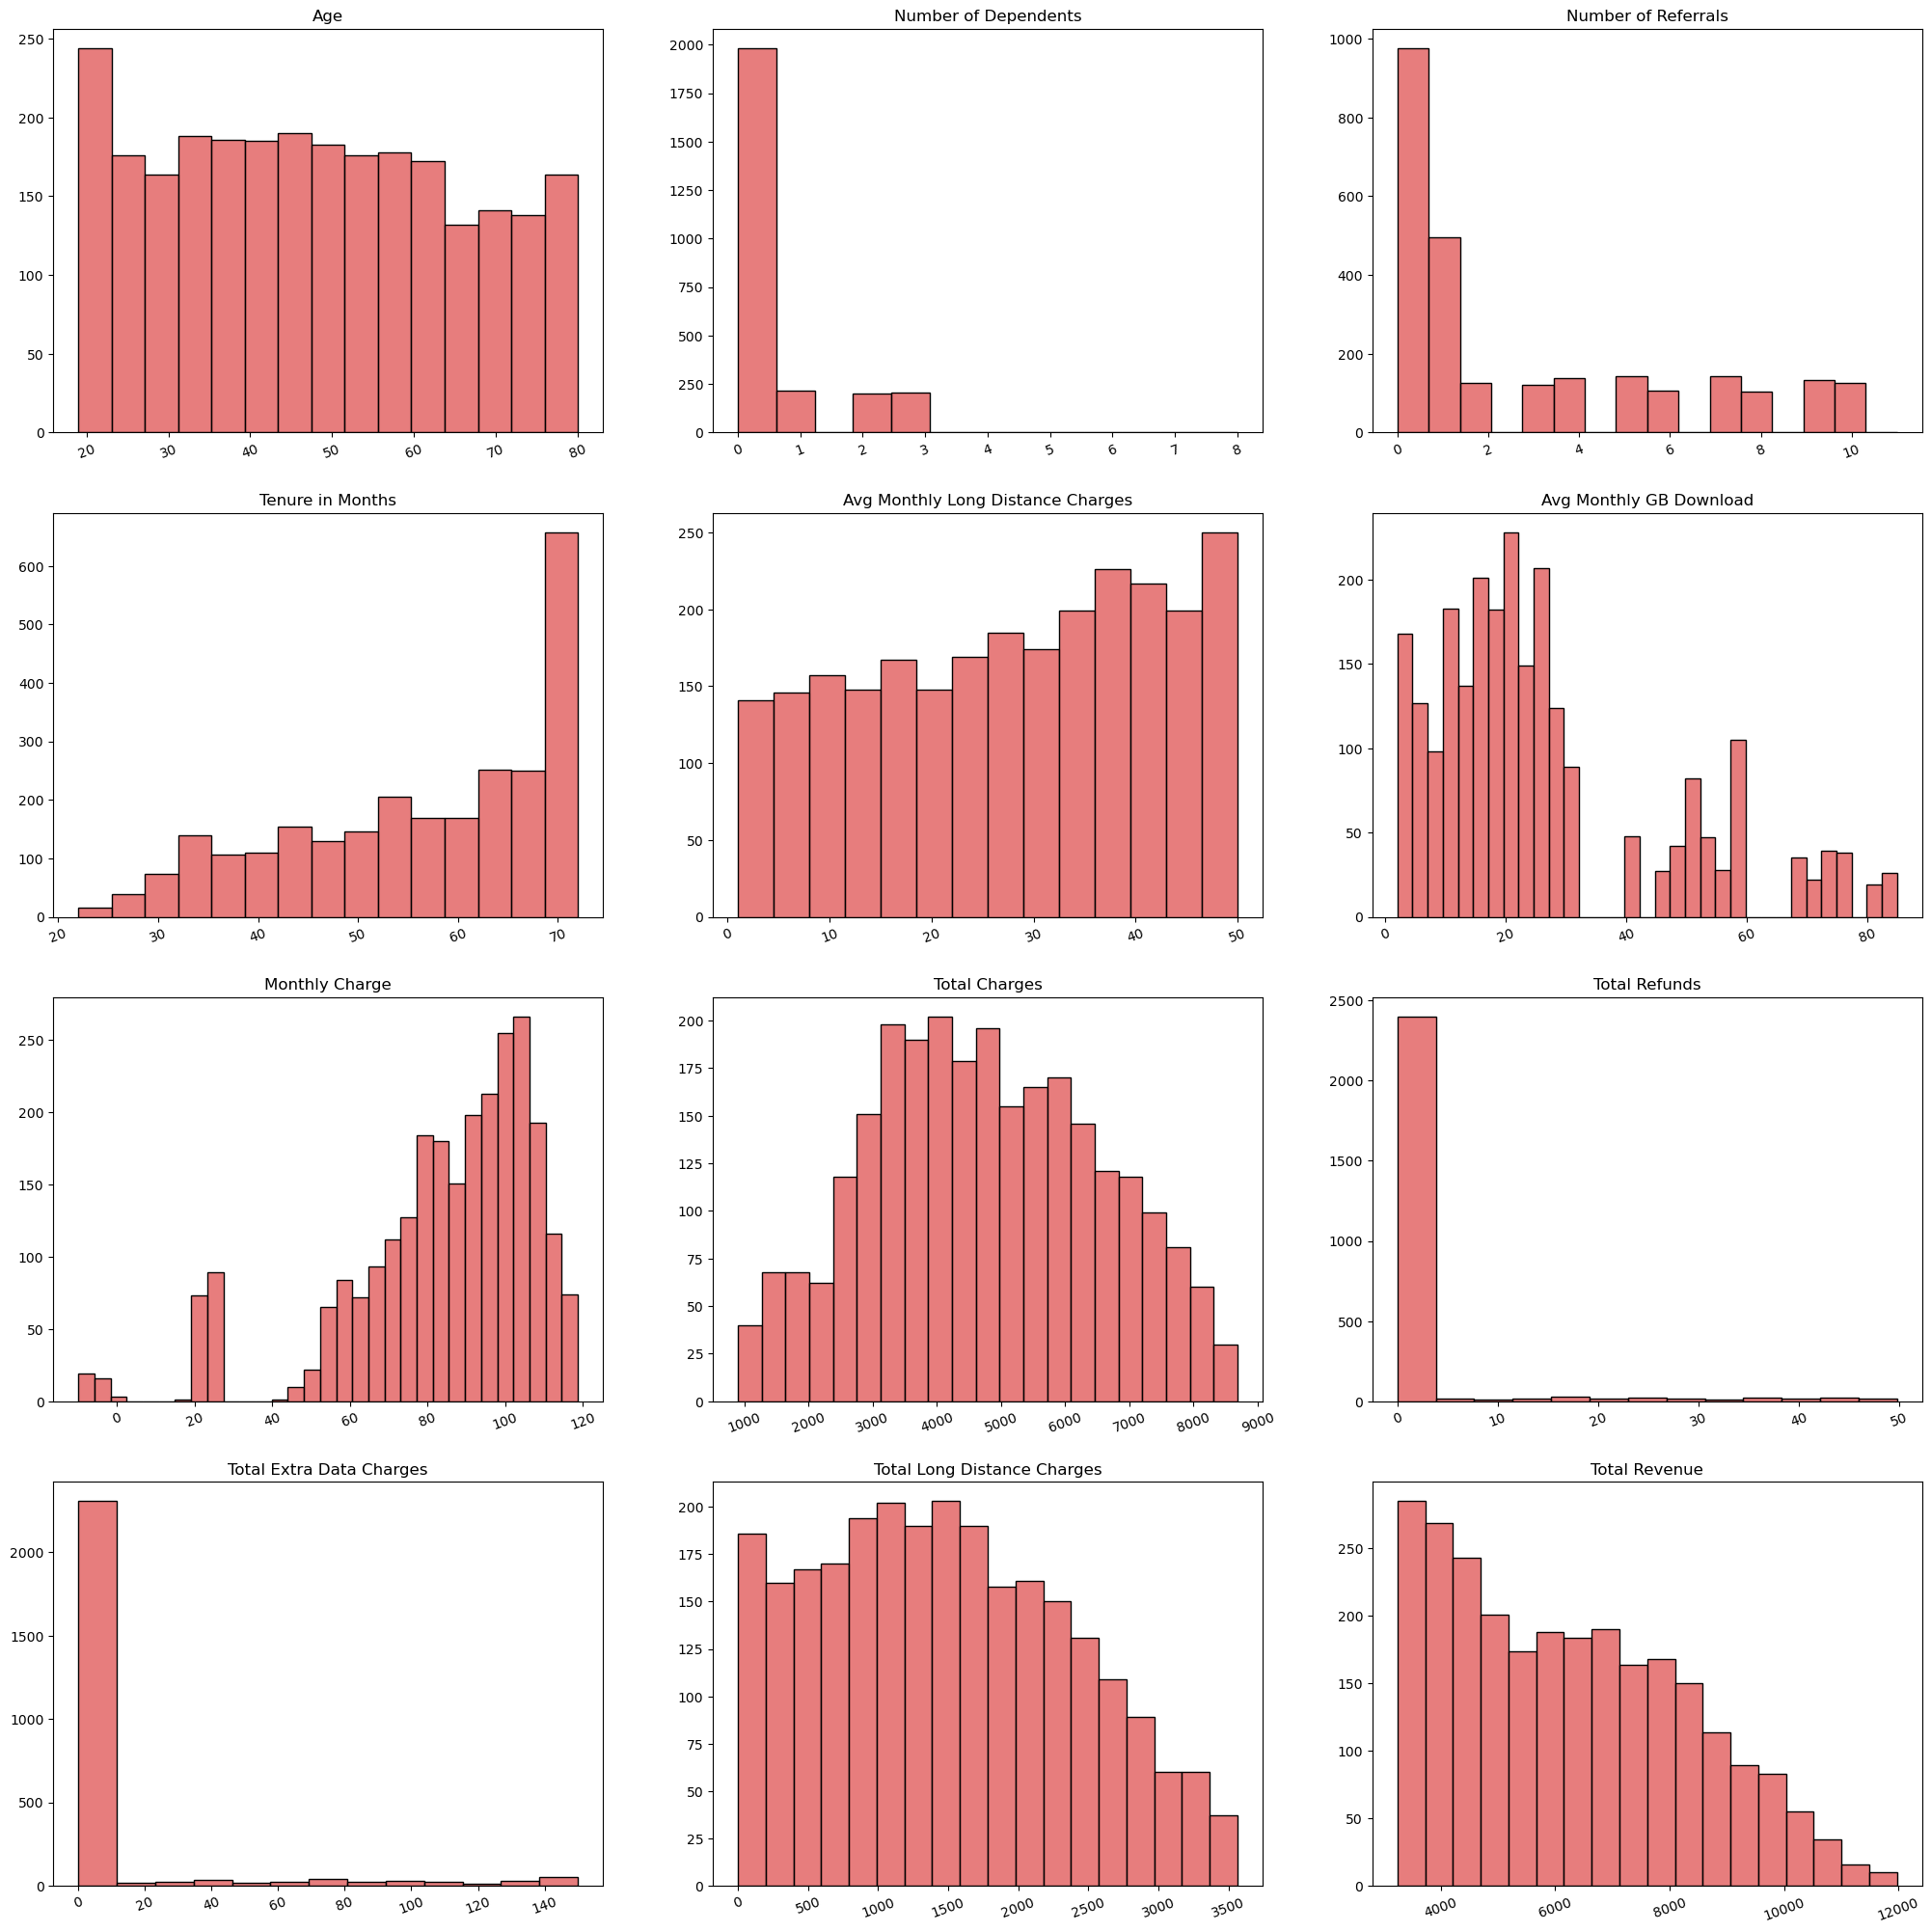

In [20]:
fig = plt.figure(figsize = (25, 25))

i = 1
for x in num:
    plt.subplot(4, 3, i)
    ax = sns.histplot(x = df_high_value[x], color = '#E05252')
    ax.set(xlabel = None, ylabel = None)
    plt.title(str(x), loc = 'center')
    plt.xticks(rotation = 20, fontsize = 10)
    i += 1

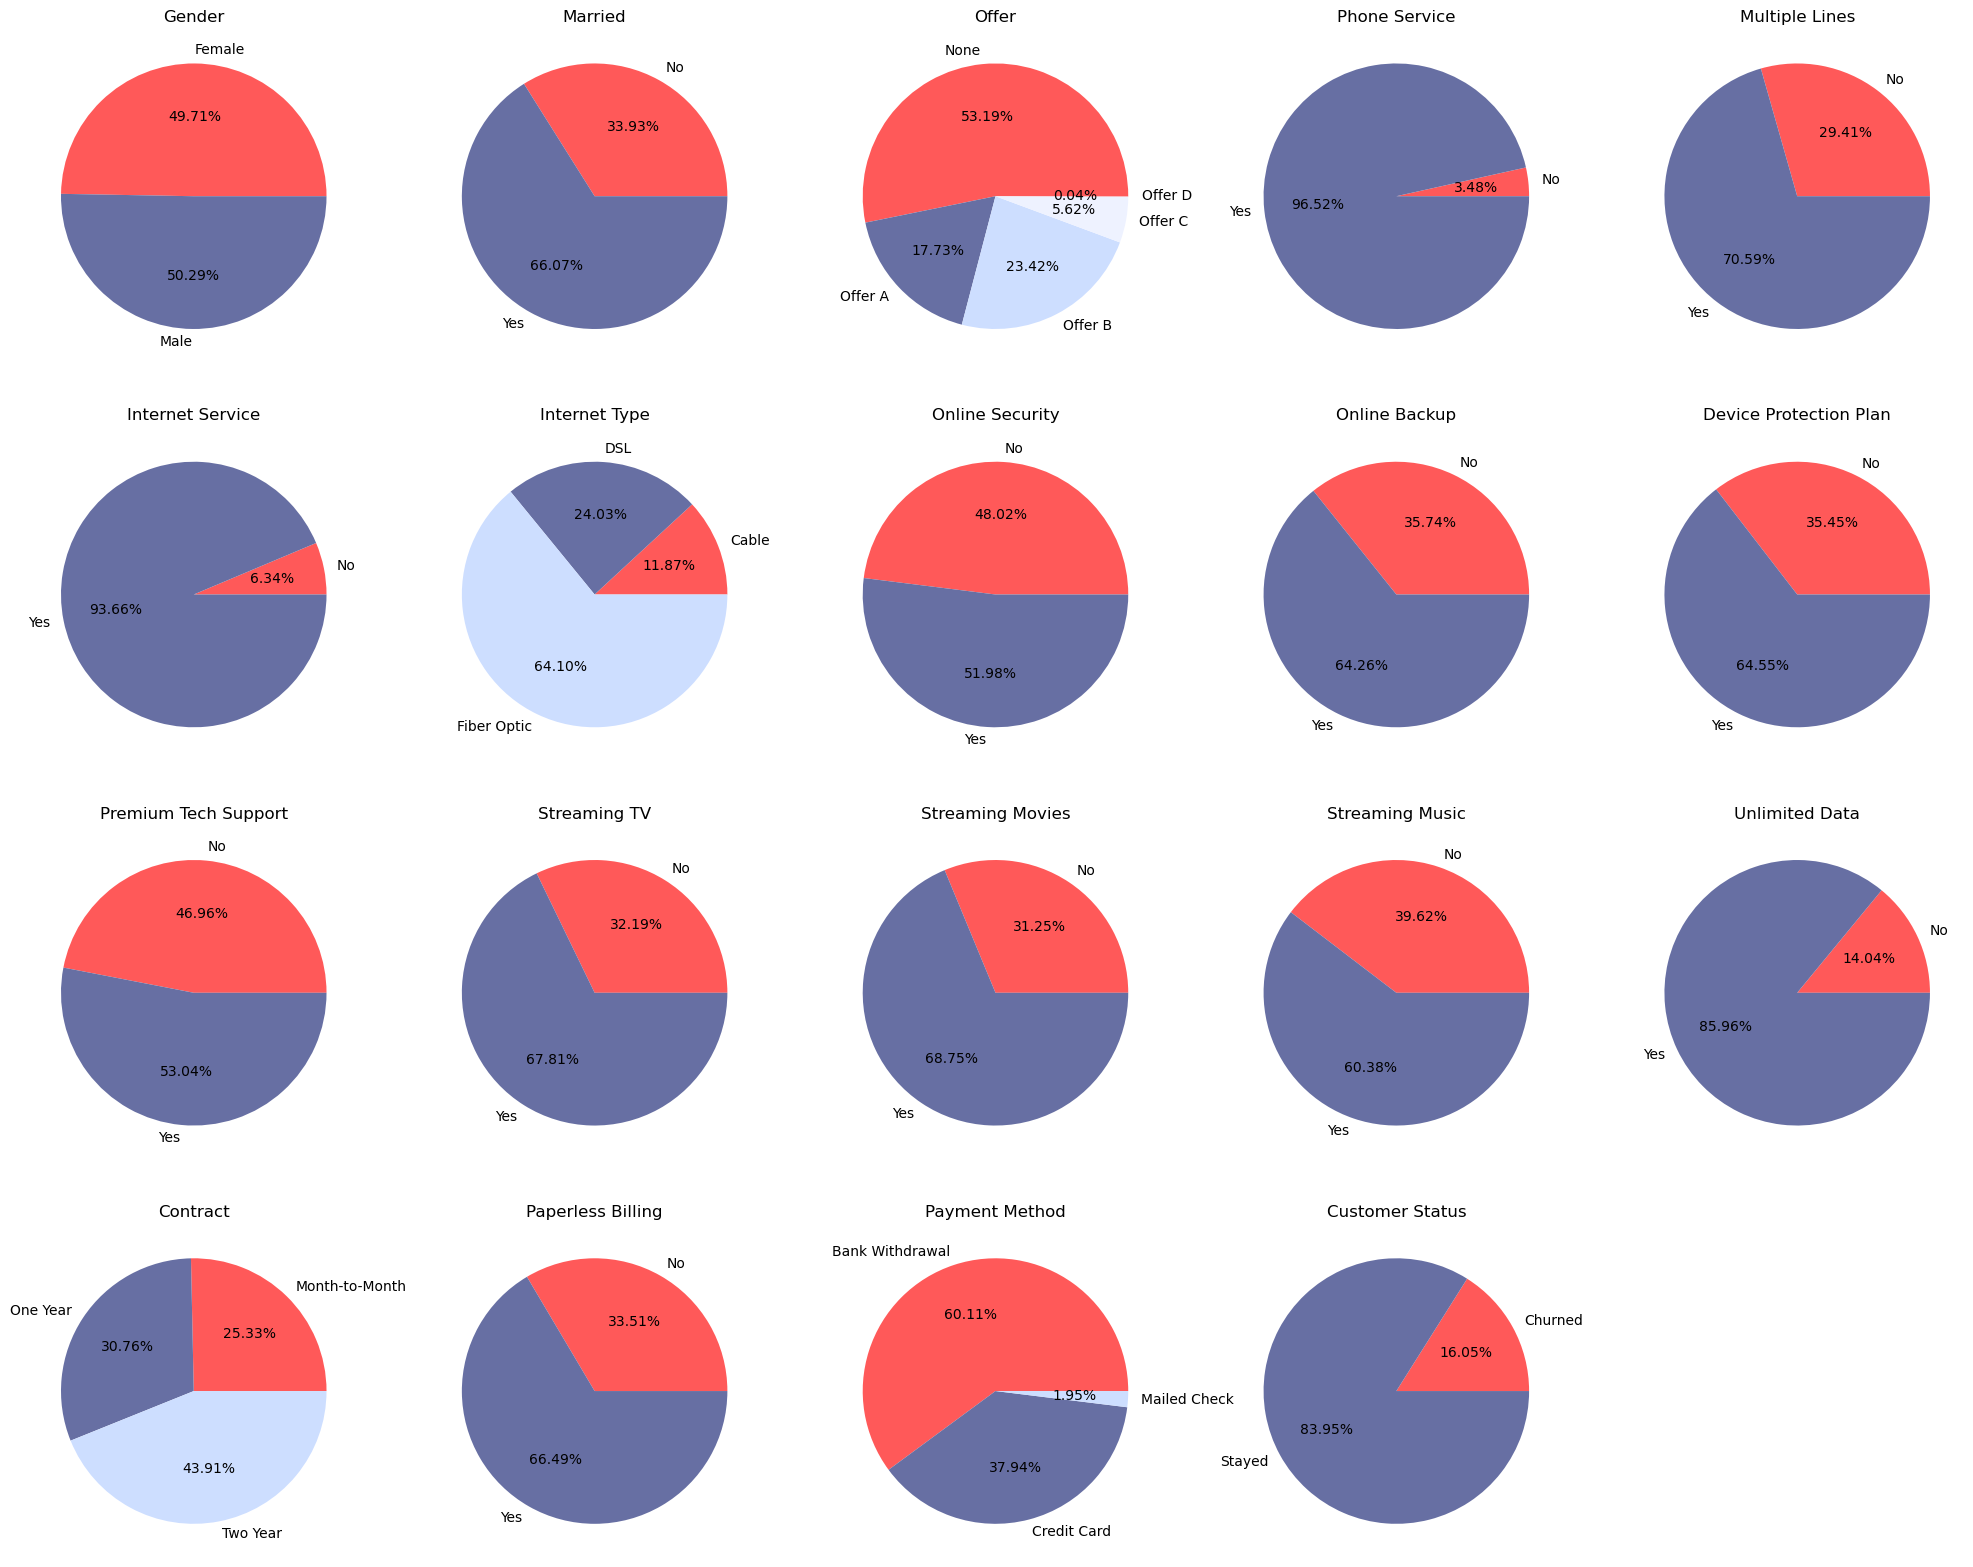

In [21]:
fig = plt.figure(figsize = (25, 25))
i=1
for x in cat:
    plt.subplot(5, 5, i)
    ax = df_high_value.groupby([x]).size().plot(kind = 'pie', autopct = '%.2f%%', colors = ['#FF5959', '#676FA3','#CDDEFF', '#EEF2FF'])
    ax.set(xlabel = None, ylabel = None)
    plt.title(str(x), loc='center')
    i+=1
plt.show()

### Churn Customers Analysis

In [22]:
df_churned = data_customer.loc[data_customer['Customer Status'] == "Churned"]

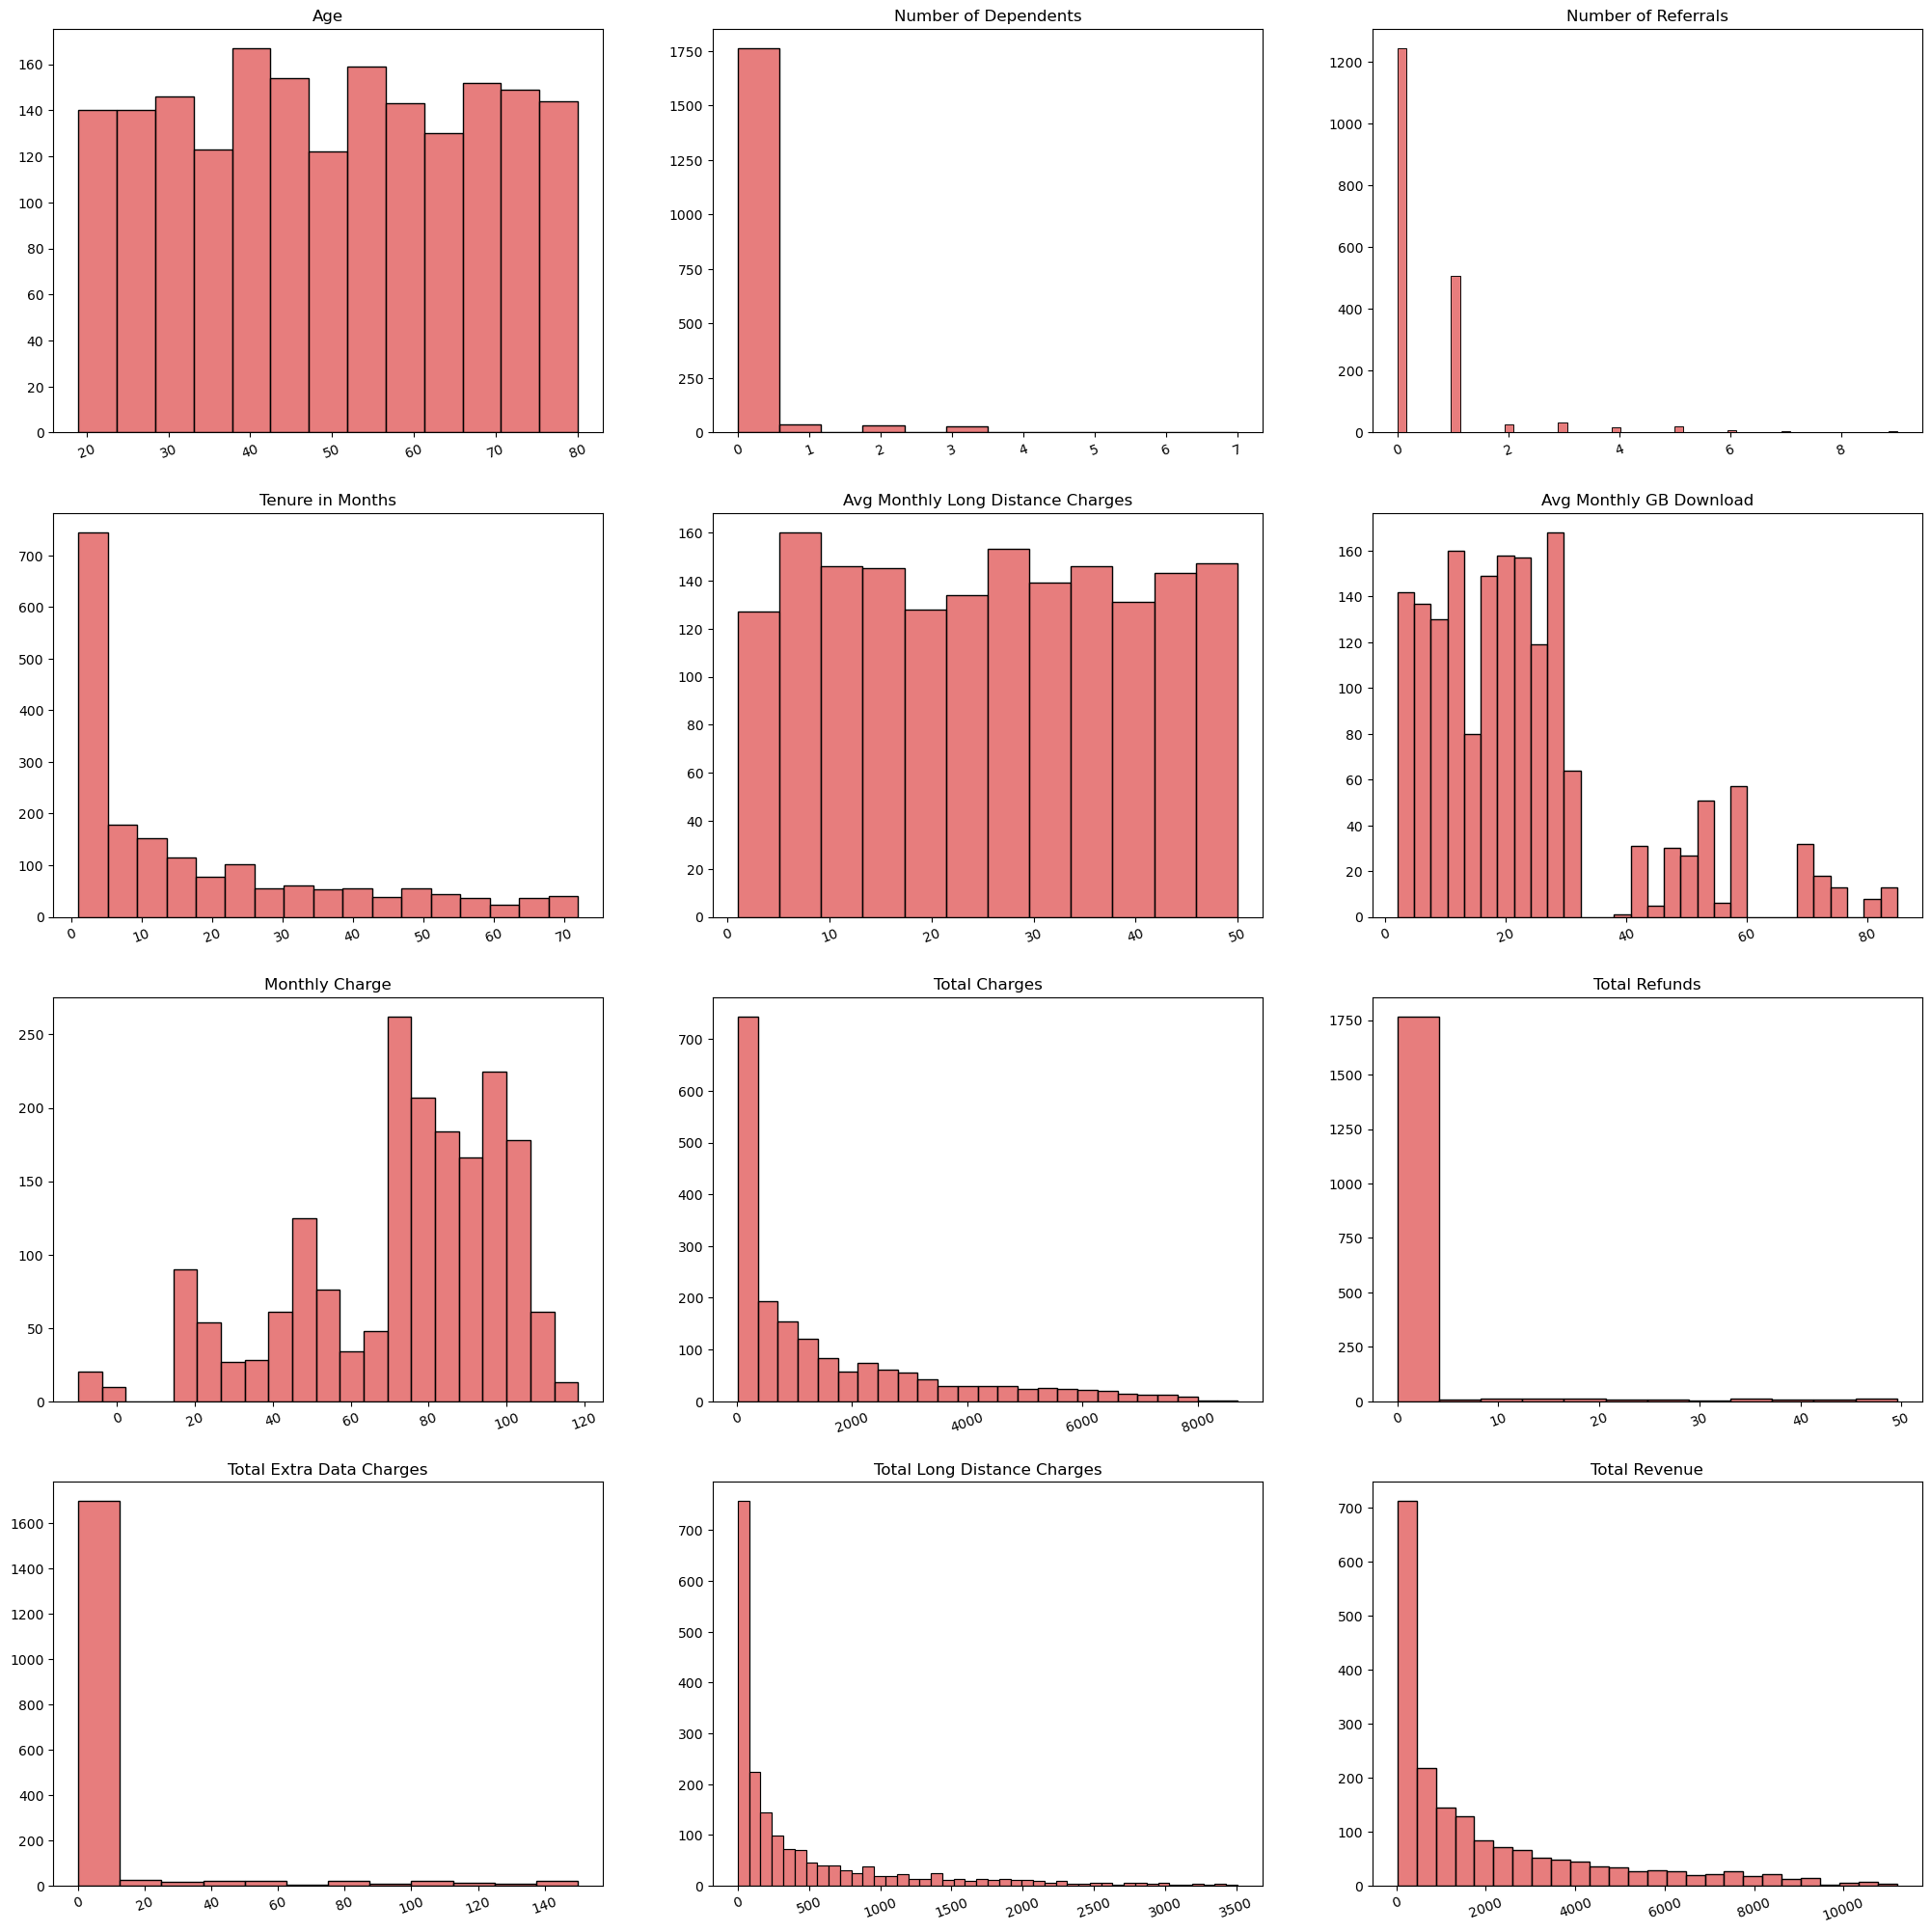

In [23]:
fig = plt.figure(figsize = (25, 25))

i = 1
for x in num:
    plt.subplot(4, 3, i)
    ax = sns.histplot(x = df_churned[x], color = '#E05252')
    ax.set(xlabel = None, ylabel = None)
    plt.title(str(x), loc = 'center')
    plt.xticks(rotation = 20, fontsize = 10)
    i += 1

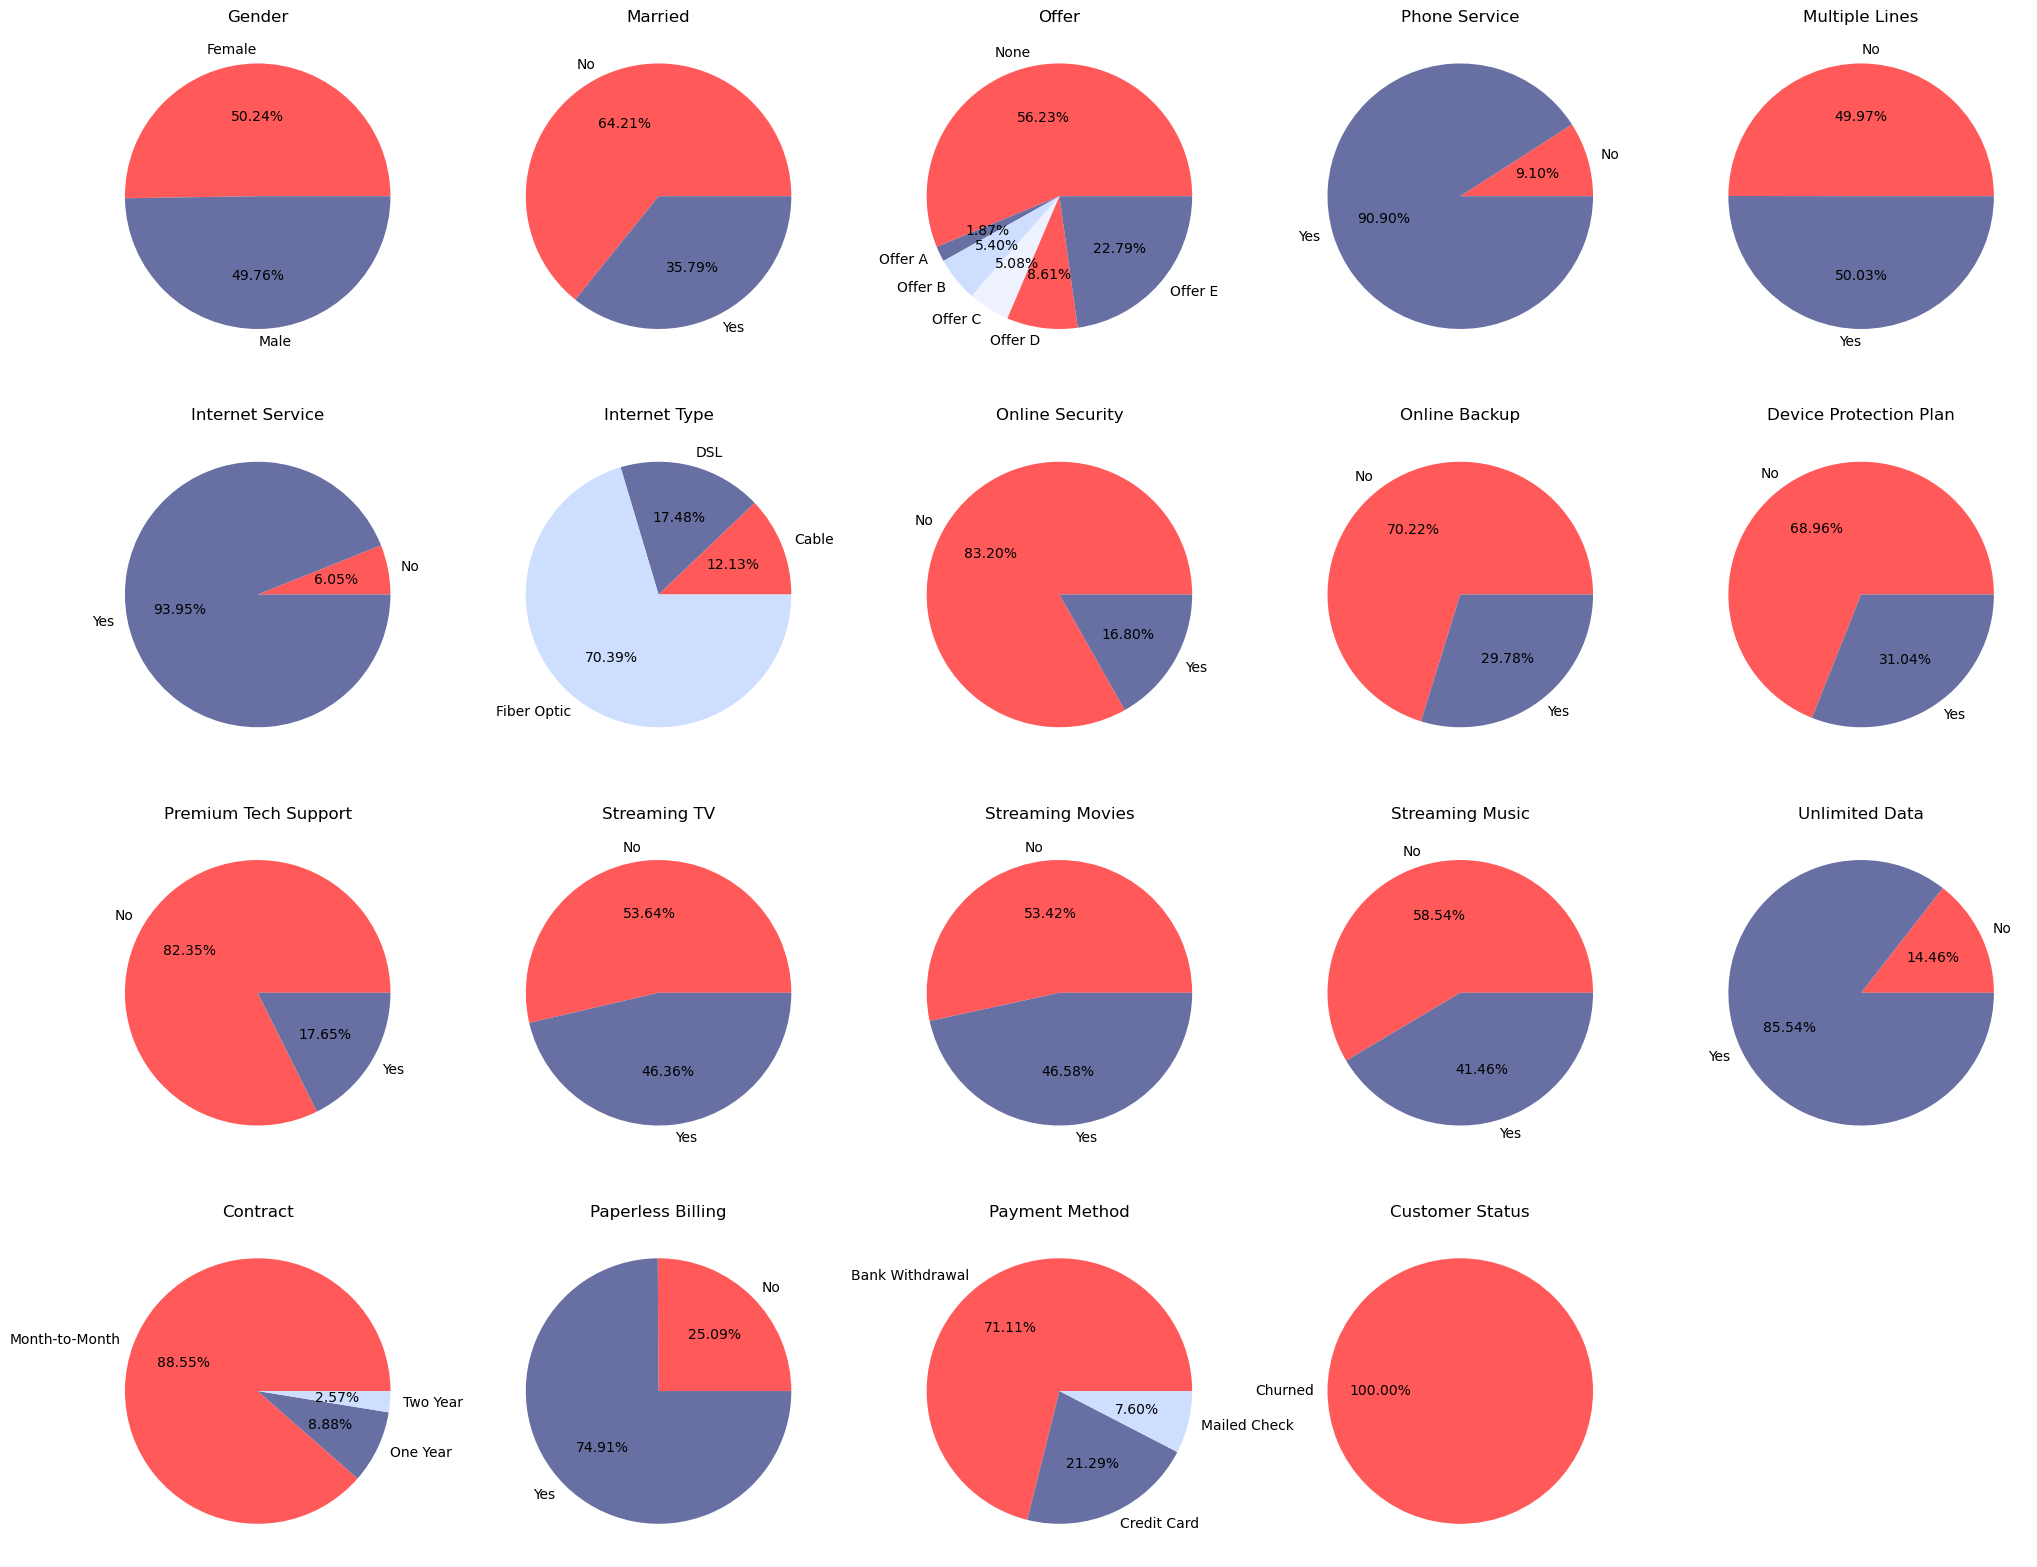

In [24]:
fig = plt.figure(figsize = (25, 25))
i=1
for x in cat:
    plt.subplot(5, 5, i)
    ax = df_churned.groupby([x]).size().plot(kind = 'pie', autopct = '%.2f%%', colors = ['#FF5959', '#676FA3','#CDDEFF', '#EEF2FF'])
    ax.set(xlabel = None, ylabel = None)
    plt.title(str(x), loc='center')
    i+=1
plt.show()

### Summary (High_Value/Churned)

1. High Value Customers Profile Recap:

    * Approximately 67.73% of these customers are married.
    * They have not made a purchase of Offer E.
    * More than 50% of this customer segment have subscribed to atleast one of these internet services (backup, security, protection plan, tech support) as well as streaming services (TV, movies, music).
    * Out of the 81.66% with long term contracts.

2. Churned Customers Profile Recap:

    * Only 35.79% of these customers are married.
    * Offer E is the favourite, indicating that the company should review this offer.
    * Over 50% of churned customers have not opted for additional internet services or streaming services.
    * A significant 88.55% of churned customers prefer a monthly billing cycle.

3. Common Traits:

    * There is an even distribution of gender among both customer groups.
    * Fiber optic internet service is the most popular among both segments of customers.
    * The majority of customers in both groups prefer unlimited data usage.
    * A significant portion of customers in both groups prefers receiving paperless billing and making payments through bank withdrawal.

Finally, If you enjoyed my Notebook feel free to leave an upvote